# Prediction, 1997-2026

The most probable composition at t past the membership cutoff, and the composition at t+h. It reads the eligibility panel written by `01_rules_and_reproduction.ipynb`, which runs first.

In [15]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

import maqi_hackathon_2 as h
from maqi_hackathon_2 import data

FIGURES = Path.cwd().parent / "figures"
FIGURES.mkdir(exist_ok=True)
INDEX_ID = "000003"
SEED_MONTH = pd.Timestamp("1996-12-31")
TARGET_N = 500

frame = data.load(index=INDEX_ID)
truth = h.composition.truth(INDEX_ID, end="2001-12-31")
published = data.index_returns(INDEX_ID)
panel = pd.read_parquet(data.store() / "turing_eligibility_panel.parquet")
returns = (frame.filter(pl.col("month_end") >= pl.date(1997, 1, 1))
           .select("month_end", "security", "market_cap_prev", "return_total_monthly")
           .unique(["month_end", "security"]).collect().to_pandas())
returns["month_end"] = pd.to_datetime(returns["month_end"]).dt.to_period("M").dt.to_timestamp("M")
truth_by_period = truth.groupby(truth["month"].dt.to_period("M"))["security"].apply(set)
test_months = pd.date_range("1997-01-31", "2001-12-31", freq="ME")

## Baselines

Persistence carries a known composition forward, frozen at the 1996-12 cutoff for every month of 1997-2001 or taken h months before each month, and additions and deletions are counted against that same reference. The top-N-by-cap rule with a hysteresis band is not implemented in our code: we quote the brief's overlaps for it, 0.78 frozen at 1996-12 and 0.83 at 12 months. Our persistence overlaps are 0.8293 and 0.9251, against 0.83 and 0.93 in the brief.

In [16]:
def persistence_ahead(hm, targets):
    reference = pd.DataFrame([(p.to_timestamp("M"), s) for p in targets if p - hm in truth_by_period.index
                              for s in truth_by_period[p - hm]], columns=["month", "security"])
    return reference.assign(probability=1.0), reference


seed_set = truth_by_period[SEED_MONTH.to_period("M")]
persistence = h.composition.persistence(truth, asof=SEED_MONTH, months=test_months)
persistence_12m, reference_12m = persistence_ahead(12, test_months.to_period("M"))
baselines = pd.DataFrame({
    "persistence, frozen at 1996-12": h.composition.score(persistence, truth, reference=seed_set),
    "persistence, 12 months ahead": h.composition.score(persistence_12m, truth, reference=reference_12m),
}).T
print(baselines.round(4))

                                overlap  additions_recall  \
persistence, frozen at 1996-12   0.8293               0.0   
persistence, 12 months ahead     0.9251               0.0   

                                additions_precision  deletions_recall   brier  
persistence, frozen at 1996-12                  0.0            0.0024  0.2781  
persistence, 12 months ahead                    0.0            0.0011  0.1383  


## Prediction 1: the composition at t

A recursion from the last observed composition, with market data and filings known at each month end: keep every previous member that still trades, fill the free slots with names passing the three entry screens of `01`, first towards each sector's share of large-cap value and then by cap, and if the screens run out, with the largest remaining names (`fallback`). The 500 selected names get probability 1.

In [17]:
def select_proxy_month(g, previous_members, target_n=TARGET_N):
    g = g.loc[g["active_proxy"] & g["security"].notna()]
    if g.empty:
        return pd.DataFrame()
    selected = (g.loc[g["security"].isin(previous_members)].sort_values("company_cap_3m", ascending=False)
                .drop_duplicates("security").head(target_n).assign(selection_source="retained"))
    slots = target_n - len(selected)
    if slots <= 0:
        return selected
    candidates = (g.loc[g["eligible_2001_proxy"] & ~g["security"].isin(set(selected["security"]))]
                  .sort_values("company_cap_3m", ascending=False))
    sector_universe = g.loc[g["base_universe"] & g["large_cap_proxy"] & g["gics_sector"].notna()]
    if not sector_universe.empty:
        weights = sector_universe.groupby("gics_sector")["company_cap_3m"].sum()
        target_counts = (weights / weights.sum() * target_n).round().astype(int).sort_values(ascending=False)
        retained_counts = selected["gics_sector"].value_counts()
        picks = []
        for sector, target_count in target_counts.items():
            if slots <= 0:
                break
            need = max(int(target_count) - int(retained_counts.get(sector, 0)), 0)
            take = candidates.loc[candidates["gics_sector"] == sector].head(min(need, slots))
            if len(take):
                picks.append(take.assign(selection_source="sector_fill"))
                candidates = candidates.loc[~candidates["security"].isin(set(take["security"]))]
                slots -= len(take)
        selected = pd.concat([selected, *picks], ignore_index=True)
    if slots > 0:
        take = candidates.loc[~candidates["security"].isin(set(selected["security"]))].head(slots)
        selected = pd.concat([selected, take.assign(selection_source="global_fill")], ignore_index=True)
        slots = target_n - len(selected)
    if slots > 0:
        fallback = (g.loc[g["base_universe"] & ~g["security"].isin(set(selected["security"]))]
                    .sort_values("company_cap_3m", ascending=False).head(slots))
        selected = pd.concat([selected, fallback.assign(selection_source="fallback")], ignore_index=True)
    return selected.drop_duplicates("security").head(target_n)


def run_proxy(seed, months):
    previous, rows, sources = set(seed), [], []
    for month in months:
        selected = select_proxy_month(panel.loc[panel["month_end"] == month], previous)
        if selected.empty:
            continue
        rows.append(pd.DataFrame({"month": month, "security": selected["security"].to_numpy(), "probability": 1.0}))
        sources.append(selected["selection_source"].value_counts().to_dict() | {"month": month})
        previous = set(selected["security"])
    return pd.concat(rows, ignore_index=True), pd.DataFrame(sources).set_index("month").fillna(0)

The honest test: membership frozen at 1996-12, scored on 1997-2001 against the 1996-12 composition. The proxy scores overlap 0.4619, additions recall 0.4139 with precision 0.1647 and deletions recall 0.9823, against 0.8293 overlap and deletions recall 0.0024 for persistence; `fallback` fills 589 slots over the five years, 499 of them in 1998. The proxy fails here because monthly caps are missing before 1998-04: through 1997 it keeps about ten names a month and refills the book only in 1998, so a deletions recall near 1 comes from dropping almost every member. The index on it scores correlation 0.6842 and slope 0.3493, but the same monthly build on the observed composition scores 0.6231 and 0.4381, so this check says nothing before 1998.

In [18]:
def holdings_index(holdings):
    x = (holdings.assign(month_end=holdings["month"] + pd.offsets.MonthEnd(1))
         .merge(returns, on=["month_end", "security"]))
    x = x.loc[x["market_cap_prev"].gt(0) & x["return_total_monthly"].notna()]
    return ((x["market_cap_prev"] * x["return_total_monthly"]).groupby(x["month_end"]).sum()
            / x.groupby("month_end")["market_cap_prev"].sum())


def as_holdings(sets):
    return pd.DataFrame([(p.to_timestamp("M"), s) for p, members in sets.items() for s in members],
                        columns=["month", "security"])


def score_table(series):
    out = pd.DataFrame({name: h.score(s, published) for name, s in series.items()}).T
    out["tracking_error_bp"] = out.pop("tracking_error") * 1e4
    out["months"] = [h.monthly(s).dropna().index.intersection(published.index).size for s in series.values()]
    return out.round(4)


methodology_prediction, sources_test = run_proxy(seed_set, test_months)
p1_test = pd.DataFrame({
    "methodology proxy": h.composition.score(methodology_prediction, truth, reference=seed_set),
    "persistence, frozen at 1996-12": h.composition.score(persistence, truth, reference=seed_set),
}).T
print(p1_test.round(4))
print(sources_test.groupby(sources_test.index.year).sum())
seed_holdings = pd.DataFrame({"month": SEED_MONTH, "security": sorted(seed_set)})
print(score_table({
    "observed composition": holdings_index(as_holdings({p: s for p, s in truth_by_period.items() if p >= SEED_MONTH.to_period("M")})),
    "methodology proxy": holdings_index(pd.concat([seed_holdings, methodology_prediction[["month", "security"]]])),
    "persistence, frozen at 1996-12": holdings_index(pd.concat([seed_holdings, persistence[["month", "security"]]])),
}))

                                overlap  additions_recall  \
methodology proxy                0.4619            0.4139   
persistence, frozen at 1996-12   0.8293            0.0000   

                                additions_precision  deletions_recall   brier  
methodology proxy                            0.1647            0.9823  0.6661  
persistence, frozen at 1996-12               0.0000            0.0024  0.2781  
       fallback  retained  global_fill  sector_fill
month                                              
1997       11.0       123          0.0          0.0
1998      499.0      4030          5.0          0.0
1999       25.0      5974          0.0          1.0
2000       28.0      5972          0.0          0.0
2001       26.0      5974          0.0          0.0
                                correlation   slope  tracking_error_bp  months
observed composition                 0.6231  0.4381          1989.2277      61
methodology proxy                    0.6842  0.3493   

Past the vendor's cutoff: the same recursion seeded with the 2001-12 composition, 2002-01 to 2026-06, written outside the repository as `month, security, probability`. With no membership to score it against, the check is the index built on it: correlation 0.7676, slope 0.5655, tracking error 1,298 bp against the published total return over 294 months, 1,851 bp on 2002-2009 and 663 bp from 2020 (correlation 0.9225, slope 0.9844). The recursion adds 5 to 27 names a year, against 9 to 53 for the real index on 1990-2001. We did not run the construction on the Nasdaq-100, whose membership runs past 2002 but whose level is price only.

names added per year: {2002: 8.0, 2003: 8.0, 2004: 13.0, 2005: 11.0, 2006: 27.0, 2007: 26.0, 2008: 21.0, 2009: 16.0, 2010: 12.0, 2011: 14.0, 2012: 16.0, 2013: 13.0, 2014: 12.0, 2015: 14.0, 2016: 17.0, 2017: 12.0, 2018: 11.0, 2019: 10.0, 2020: 11.0, 2021: 13.0, 2022: 19.0, 2023: 7.0, 2024: 5.0, 2025: 10.0, 2026: 8.0}
                    correlation   slope  tracking_error_bp  months
2002-01 to 2026-07       0.7676  0.5655          1297.8233     294
2002-01 to 2009-12       0.7655  0.4346          1850.9186      96
2010-01 to 2019-12       0.7643  0.6227           988.9077     120
2020-01 to 2026-07       0.9225  0.9844           662.7969      78


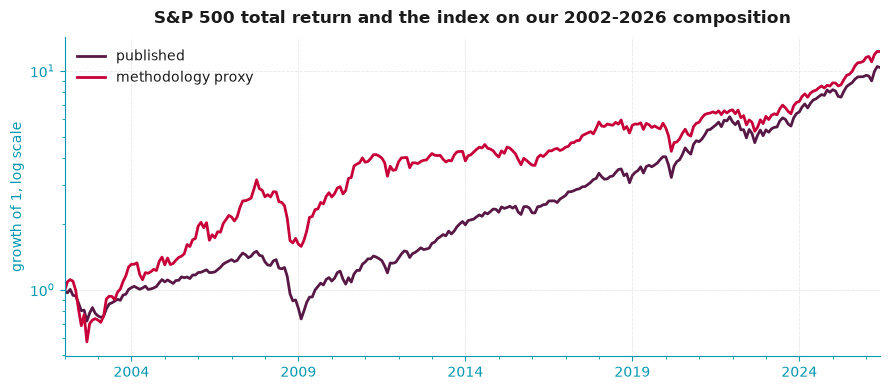

In [19]:
seed_2001 = truth_by_period[pd.Period("2001-12", freq="M")]
prediction_1, sources_2002 = run_proxy(seed_2001, pd.date_range("2002-01-31", "2026-06-30", freq="ME"))
prediction_1.to_parquet(data.store() / "turing_prediction_1_2002_2026.parquet")
proxy_index = h.monthly(holdings_index(pd.concat([
    pd.DataFrame({"month": pd.Timestamp("2001-12-31"), "security": sorted(seed_2001)}),
    prediction_1[["month", "security"]]])))
print("names added per year:", sources_2002.drop(columns="retained").sum(axis=1).groupby(sources_2002.index.year).sum().to_dict())
print(score_table({f"{a} to {b}": proxy_index[a:b] for a, b in [("2002-01", "2026-07"), ("2002-01", "2009-12"),
                                                                 ("2010-01", "2019-12"), ("2020-01", "2026-07")]}))

growth = pd.concat({"published": published, "methodology proxy": proxy_index}, axis=1).dropna()
ax = (1 + growth).cumprod().plot(logy=True, figsize=(9, 4), title="S&P 500 total return and the index on our 2002-2026 composition")
ax.set_ylabel("growth of 1, log scale")
plt.tight_layout()
plt.savefig(FIGURES / "proxy_2002_2026.png", dpi=150)

## Prediction 2: the composition at t+h

Two classifiers on 1990-2001 security-months, one for exits among members and one for entries among non-members, on size, liquidity, momentum, fundamentals known at t and time in the index. Events are rare (0.421% of member-months, 0.0212% of non-member-months), so classes are weighted and the probabilities corrected back to the base rate; the family, logit or gradient boosting, is chosen by average precision on origins 1995-12 to 1996-11, then refit on every origin up to 1996-11. Gradient boosting wins for both, average precision 0.0074 for exits and 0.0009 for entries, ROC AUC 0.68 and 0.76. We built it for h = 1 only.

In [20]:
INNER_TRAIN_LAST_ORIGIN = pd.Period("1995-11", freq="M")
VALID_FIRST_ORIGIN = pd.Period("1995-12", freq="M")
VALID_LAST_ORIGIN = pd.Period("1996-11", freq="M")
TRAIN_LAST_ORIGIN = pd.Period("1996-11", freq="M")
TEST_FIRST_ORIGIN = pd.Period("1996-12", freq="M")
TEST_LAST_ORIGIN = pd.Period("2001-11", freq="M")
ADDITION_POOL_RANK = 1500
RANDOM_STATE = 42

cols = ["security", "company_id", "month_end", "close", "volume", "market_cap", "return_total_monthly", "member",
        "period_end", "available_from", "income_before_extraordinary_items", "net_income",
        "operating_income_after_depreciation", "revenue", "total_assets", "common_equity",
        "long_term_debt", "debt_current", "cash"]
df = (frame.filter(pl.col("month_end").is_between(pl.date(1990, 1, 1), pl.date(2002, 1, 31)))
      .select(cols).collect().to_pandas())
df["month_end"] = pd.to_datetime(df["month_end"])
df["period"] = df["month_end"].dt.to_period("M")
df["member"] = df["member"].fillna(False).astype(bool)
df = df.sort_values(["security", "month_end"]).drop_duplicates(["security", "month_end"]).reset_index(drop=True)

df["target_period"] = df["period"] + 1
future = truth.assign(target_period=truth["month"].dt.to_period("M"), member_next=True)
df = df.merge(future[["target_period", "security", "member_next"]], on=["target_period", "security"], how="left")
df["member_next"] = np.where(df["target_period"].isin(set(truth_by_period.index)), df["member_next"].eq(True), np.nan)
print(f"{len(df):,} security-months, {df['security'].nunique():,} securities, "
      f"{df.loc[df['member_next'].notna(), 'period'].nunique()} origins with a known t+1")

1,404,004 security-months, 18,910 securities, 143 origins with a known t+1


In [21]:
grp = df.groupby(["month_end", "company_id"])["market_cap"]
df["company_market_cap"] = grp.transform("sum").where(grp.transform("count") > 0)
df["active_proxy"] = df["security"].notna() & df["company_id"].notna() & df["close"].gt(0)
df["log_company_cap"] = np.log1p(df["company_market_cap"].clip(lower=0))
df["cap_rank"] = df.groupby("period")["company_market_cap"].rank(method="min", ascending=False)
df["cap_percentile"] = df.groupby("period")["company_market_cap"].rank(method="average", pct=True)
member_median_cap = df.loc[df["member"] & df["company_market_cap"].gt(0)].groupby("period")["company_market_cap"].median()
df["log_cap_vs_member_median"] = np.log(df["company_market_cap"] / df["period"].map(member_median_cap))
df["turnover_1m"] = df["close"] * df["volume"] / df["company_market_cap"].replace(0, np.nan)
df["_logret"] = np.log1p(df["return_total_monthly"].astype(float).clip(lower=-0.999999))

gsec = df.groupby("security", sort=False)
df["turnover_3m"] = gsec["turnover_1m"].transform(lambda s: s.rolling(3, min_periods=2).mean())
df["turnover_12m"] = gsec["turnover_1m"].transform(lambda s: s.rolling(12, min_periods=6).mean())
for w, minp in [(3, 2), (6, 3), (12, 6)]:
    df[f"momentum_{w}m"] = np.expm1(gsec["_logret"].transform(lambda s, w=w, minp=minp: s.rolling(w, min_periods=minp).sum()))
df["volatility_12m"] = gsec["return_total_monthly"].transform(lambda s: s.rolling(12, min_periods=6).std())

earnings = df["income_before_extraordinary_items"].where(df["income_before_extraordinary_items"].notna(), df["net_income"])
assets, equity, revenue = (df[c].replace(0, np.nan) for c in ["total_assets", "common_equity", "revenue"])
df["roa_proxy"] = earnings / assets
df["roe_proxy"] = earnings / equity
df["operating_margin"] = df["operating_income_after_depreciation"] / revenue
df["leverage"] = (df["long_term_debt"].fillna(0) + df["debt_current"].fillna(0)) / assets
df["cash_to_assets"] = df["cash"] / assets
df["profitable_now"] = (earnings > 0).astype(float)

df = df.sort_values(["security", "month_end"]).reset_index(drop=True)
prev_member = df.groupby("security")["member"].shift()
prev_period = df.groupby("security")["period"].shift()
consecutive = prev_period.notna() & ((pd.Series(df["period"].array.asi8, index=df.index)
                                      - pd.Series(prev_period.array.asi8, index=df.index)) == 1)
run_id = (~consecutive | df["member"].ne(prev_member)).groupby(df["security"]).cumsum()
df["member_age_months"] = np.where(df["member"], df.groupby(["security", run_id]).cumcount().add(1), 0).astype(float)

FEATURES = ["log_company_cap", "cap_percentile", "log_cap_vs_member_median", "turnover_1m", "turnover_3m",
            "turnover_12m", "momentum_3m", "momentum_6m", "momentum_12m", "volatility_12m", "roa_proxy",
            "roe_proxy", "operating_margin", "leverage", "cash_to_assets", "profitable_now", "member_age_months"]
df[FEATURES] = df[FEATURES].replace([np.inf, -np.inf], np.nan)

In [22]:
known = df.loc[df["member_next"].notna() & df["active_proxy"]].copy()
known["member_next"] = known["member_next"].astype(bool)
deletion_data = known.loc[known["member"]].assign(event=lambda x: (~x["member_next"]).astype(int))
addition_data = known.loc[~known["member"]].assign(event=lambda x: x["member_next"].astype(int))
coverage = addition_data.loc[addition_data["event"] == 1, "cap_rank"].le(ADDITION_POOL_RANK).mean()
print(f"exits {deletion_data['event'].sum():,} of {len(deletion_data):,} member-months ({deletion_data['event'].mean():.3%}); "
      f"entries {addition_data['event'].sum():,} of {len(addition_data):,} non-member-months ({addition_data['event'].mean():.4%}); "
      f"entries within the top {ADDITION_POOL_RANK} by cap: {coverage:.1%}")


def make_model(kind):
    if kind == "logit":
        return Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler()),
                         ("model", LogisticRegression(C=0.5, max_iter=3000, random_state=RANDOM_STATE))])
    return Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                     ("model", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=180, max_leaf_nodes=15,
                                                              min_samples_leaf=30, l2_regularization=1.0,
                                                              random_state=RANDOM_STATE))])


def fit_balanced(model, X, y):
    return model.fit(X, y, model__sample_weight=compute_sample_weight(class_weight="balanced", y=y))


def correct_balanced_prior(q, true_event_rate):
    q = np.clip(np.asarray(q, dtype=float), 1e-8, 1 - 1e-8)
    pi = float(np.clip(true_event_rate, 1e-8, 1 - 1e-8))
    return pi * q / (pi * q + (1 - pi) * (1 - q))


def event_probability(model, X, true_event_rate):
    return correct_balanced_prior(model.predict_proba(X)[:, 1], true_event_rate)

exits 301 of 71,439 member-months (0.421%); entries 277 of 1,308,469 non-member-months (0.0212%); entries within the top 1500 by cap: 51.6%


In [23]:
def temporal_split_event_data(events):
    return (events.loc[events["period"] <= INNER_TRAIN_LAST_ORIGIN],
            events.loc[events["period"].between(VALID_FIRST_ORIGIN, VALID_LAST_ORIGIN)])


def compare_families(events, event_name):
    train, valid = temporal_split_event_data(events)
    rows = []
    for kind in ["logit", "histgb"]:
        model = fit_balanced(make_model(kind), train[FEATURES], train["event"])
        p = event_probability(model, valid[FEATURES], train["event"].mean())
        rows.append({"event": event_name, "model": kind, "average_precision": average_precision_score(valid["event"], p),
                     "roc_auc": roc_auc_score(valid["event"], p)})
    return pd.DataFrame(rows).sort_values("average_precision", ascending=False)


selection = pd.concat([compare_families(deletion_data, "deletion"), compare_families(addition_data, "addition")])
print(selection.round(4))
best_delete_kind = selection.loc[selection["event"] == "deletion", "model"].iloc[0]
best_add_kind = selection.loc[selection["event"] == "addition", "model"].iloc[0]

delete_train = deletion_data.loc[deletion_data["period"] <= TRAIN_LAST_ORIGIN]
add_train = addition_data.loc[addition_data["period"] <= TRAIN_LAST_ORIGIN]
delete_model = fit_balanced(make_model(best_delete_kind), delete_train[FEATURES], delete_train["event"])
add_model = fit_balanced(make_model(best_add_kind), add_train[FEATURES], add_train["event"])
DELETE_PRIOR, ADD_PRIOR = delete_train["event"].mean(), add_train["event"].mean()
print(f"exits: {best_delete_kind}, prior {DELETE_PRIOR:.4%}; entries: {best_add_kind}, prior {ADD_PRIOR:.4%}")

      event   model  average_precision  roc_auc
1  deletion  histgb             0.0074   0.6839
0  deletion   logit             0.0065   0.7048
1  addition  histgb             0.0009   0.7587
0  addition   logit             0.0004   0.7266
exits: histgb, prior 0.2628%; entries: histgb, prior 0.0146%


At t+1 the forecast keeps the N names with the highest probability, N the number of members at t: overlap 0.9926 against 0.9932 for persistence, additions recall 0 and deletions recall 0.0026. The models predict 0.00 additions and 0.40 deletions a month, for 3.22 and 3.22 in the truth.

In [24]:
def forecast_next_month(origin_frame):
    origin_frame = origin_frame.loc[origin_frame["active_proxy"]].drop_duplicates("security").copy()
    target_n = int(origin_frame["member"].sum())
    origin_frame["p_member_next"] = 0.0
    incumbent = origin_frame["member"]
    candidate = ~origin_frame["member"] & origin_frame["cap_rank"].le(ADDITION_POOL_RANK)
    if incumbent.any():
        origin_frame.loc[incumbent, "p_member_next"] = 1.0 - event_probability(
            delete_model, origin_frame.loc[incumbent, FEATURES], DELETE_PRIOR)
    if candidate.any():
        origin_frame.loc[candidate, "p_member_next"] = event_probability(
            add_model, origin_frame.loc[candidate, FEATURES], ADD_PRIOR)
    ranked = origin_frame.sort_values(["p_member_next", "company_market_cap"], ascending=[False, False])
    return origin_frame, set(ranked.head(target_n)["security"])


forecast_sets, ml_rows = {}, []
for origin in pd.period_range(TEST_FIRST_ORIGIN, TEST_LAST_ORIGIN, freq="M"):
    prob_frame, forecast_sets[origin + 1] = forecast_next_month(df.loc[df["period"] == origin])
    ml_rows.append(prob_frame[["security", "p_member_next"]].assign(month=(origin + 1).to_timestamp("M")))
ml_prediction = pd.concat(ml_rows, ignore_index=True).rename(columns={"p_member_next": "probability"})
ml_prediction.to_parquet(data.store() / "turing_prediction_2_h1_1997_2001.parquet")

persistence_1m, reference_1m = persistence_ahead(1, list(forecast_sets))
p2 = pd.DataFrame({
    "entry/exit models, h=1": h.composition.score(ml_prediction, truth, reference=reference_1m),
    "persistence, h=1": h.composition.score(persistence_1m, truth, reference=reference_1m),
}).T
print(p2.round(4))
print(pd.DataFrame([{"true additions": len(truth_by_period[p] - truth_by_period[p - 1]),
                     "predicted additions": len(s - truth_by_period[p - 1]),
                     "true deletions": len(truth_by_period[p - 1] - truth_by_period[p]),
                     "predicted deletions": len(truth_by_period[p - 1] - s)}
                    for p, s in forecast_sets.items()]).mean().round(2))

                        overlap  additions_recall  additions_precision  \
entry/exit models, h=1   0.9926               0.0                  0.0   
persistence, h=1         0.9932               0.0                  0.0   

                        deletions_recall   brier  
entry/exit models, h=1            0.0026  0.0006  
persistence, h=1                  0.0000  0.0127  
true additions         3.22
predicted additions    0.00
true deletions         3.22
predicted deletions    0.40
dtype: float64


How far ahead: persistence keeps an overlap of 0.9932 at 1 month, 0.9251 at 12 and 0.7409 at 60, and adds nothing by construction. Frozen at 1996-12, the proxy goes from 0.002 after one month to 0.576 after five years, against 0.990 to 0.662 for persistence, its start being the missing caps of 1997; the models at h = 1 sit at 0.9926.

    overlap  additions_recall  additions_precision  deletions_recall   brier
1    0.9932               0.0                  0.0            0.0000  0.0127
3    0.9806               0.0                  0.0            0.0000  0.0375
6    0.9616               0.0                  0.0            0.0009  0.0731
12   0.9251               0.0                  0.0            0.0011  0.1383
24   0.8622               0.0                  0.0            0.0009  0.2406
36   0.8117               0.0                  0.0            0.0010  0.3150
48   0.7709               0.0                  0.0            0.0012  0.3707
60   0.7409               0.0                  0.0            0.0011  0.4090
     proxy  persistence
1   0.0020       0.9900
12  0.0020       0.9400
24  0.6400       0.8660
36  0.6300       0.7960
48  0.5932       0.7074
60  0.5760       0.6620


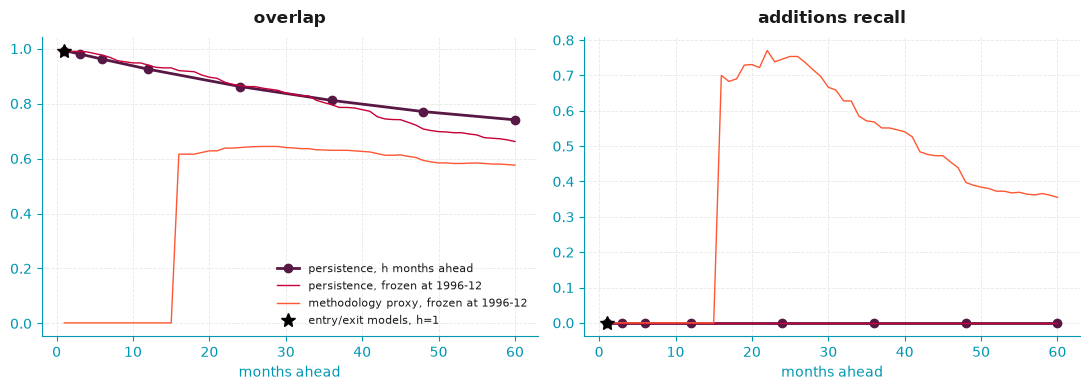

In [25]:
HORIZONS = [1, 3, 6, 12, 24, 36, 48, 60]


def persistence_score(hm):
    prediction, reference = persistence_ahead(hm, test_months.to_period("M"))
    return h.composition.score(prediction, truth, reference=reference)


def by_month(prediction, reference):
    out = pd.DataFrame({m: h.composition.score(g, truth, reference=reference) for m, g in prediction.groupby("month")}).T
    out.index = [(pd.Period(m, freq="M") - SEED_MONTH.to_period("M")).n for m in out.index]
    return out


by_horizon = pd.DataFrame({hm: persistence_score(hm) for hm in HORIZONS}).T
frozen_proxy = by_month(methodology_prediction, seed_set)
frozen_persistence = by_month(persistence, seed_set)
print(by_horizon.round(4))
print(pd.DataFrame({"proxy": frozen_proxy["overlap"], "persistence": frozen_persistence["overlap"]})
      .reindex([1, 12, 24, 36, 48, 60]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["overlap", "additions_recall"]):
    ax.plot(by_horizon.index, by_horizon[metric], "o-", label="persistence, h months ahead")
    ax.plot(frozen_persistence.index, frozen_persistence[metric], lw=1, label="persistence, frozen at 1996-12")
    ax.plot(frozen_proxy.index, frozen_proxy[metric], lw=1, label="methodology proxy, frozen at 1996-12")
    ax.plot([1], [p2.loc["entry/exit models, h=1", metric]], "k*", ms=10, label="entry/exit models, h=1")
    ax.set_xlabel("months ahead")
    ax.set_title(metric.replace("_", " "))
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "score_vs_horizon.png", dpi=150)

## Which score

We rely on additions recall and precision and deletions recall, counted against the composition at the origin, with overlap next to them: overlap alone rewards doing nothing, and persistence scores 0.9932 on it at one month without catching a single change. Brier averages over every name a prediction lists, so near-zero rows lower it: persistence goes from 0.0127 to 0.0005 when the models' universe is listed with zeros, below the models' 0.0006. The index built on a composition is a lenient judge: at h = 1 the models and persistence give the same index, within 0.5 bp of tracking error of the observed composition's.

In [26]:
same_universe = (pd.concat([ml_prediction[["month", "security"]], reference_1m]).drop_duplicates()
                 .merge(reference_1m.assign(probability=1.0), on=["month", "security"], how="left")
                 .fillna({"probability": 0.0}))
print(pd.Series({
    "entry/exit models, its universe": p2.loc["entry/exit models, h=1", "brier"],
    "persistence, members only": p2.loc["persistence, h=1", "brier"],
    "persistence, on the models' universe": h.composition.score(same_universe, truth, reference=reference_1m)["brier"],
}).round(5))
print(score_table({
    "observed composition": holdings_index(as_holdings({p: truth_by_period[p] for p in forecast_sets})),
    "persistence, h=1": holdings_index(as_holdings({p: truth_by_period[p - 1] for p in forecast_sets})),
    "entry/exit models, h=1": holdings_index(as_holdings(forecast_sets)),
}))

entry/exit models, its universe         0.00057
persistence, members only               0.01274
persistence, on the models' universe    0.00054
dtype: float64
                        correlation   slope  tracking_error_bp  months
observed composition         0.6672  0.4736          1868.2794      60
persistence, h=1             0.6661  0.4734          1868.7360      60
entry/exit models, h=1       0.6661  0.4734          1868.7360      60


## Parameters

| parameter | value | why | what else we tried |
|---|---|---|---|
| `SEED_MONTH` | 1996-12 | the brief's cutoff, leaving five years of truth to score | none |
| `TARGET_N` | 500 | the nominal size of the index | none |
| sector targets | 500 × sector share of large-cap value | the methodology balances sectors | none |
| `ADDITION_POOL_RANK` | 1500 | candidates are scored among the 1,500 largest companies only, which hold 51.6% of true additions | training on that pool only, in the earlier version (cutoff 1995-12) |
| model settings | logit C = 0.5; boosting: learning rate 0.05, 180 iterations, 15 leaves, 30 per leaf, L2 1.0 | set by hand, not tuned | none |
| model family | per event, the higher average precision on origins 1995-12 to 1996-11 | a ranking metric for rare events, measured before the cutoff | the other family |
| class weights | balanced, then prior correction | events are rare; the correction maps weighted scores back to probabilities | none |
| splits | fit to origin 1995-11, validate 1995-12 to 1996-11, refit to 1996-11, test 1996-12 to 2001-11 | nothing after the cutoff fits or chooses anything | cutoff 1995-12, in the earlier version |
| `RANDOM_STATE` | 42 | reproducible fits | none |
| `HORIZONS` | 1 to 60 months | up to the five years of truth after the cutoff | none |

## Takeaways

- Frozen at 1996-12, the proxy scores overlap 0.4619 on 1997-2001 against 0.8293 for persistence, with additions recall 0.4139 and precision 0.1647, a result driven by the missing monthly caps of 1997.
- Past 2002 the index on the proxy composition scores correlation 0.7676, slope 0.5655 and tracking error 1,298 bp against the published total return, 663 bp from 2020.
- At h = 1 the entry and exit models score overlap 0.9926 against 0.9932 for persistence and add 0 names a month, for 3.22 in the truth.
- Persistence overlap falls from 0.9932 at 1 month to 0.7409 at 60 months.